# Step 2: Technical features and the Up/Down target

Input: `data/sp500_raw.csv` from step 1. Output: `data/features.csv`.
Run the cells one by one and check the output after each.

## 2.1 Load the prices

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

prices = pd.read_csv("data/sp500_raw.csv", parse_dates=["Date"]).sort_values("Date").reset_index(drop=True)
print(prices.shape, prices["Date"].min().date(), "to", prices["Date"].max().date())
prices.head()

(1994, 7) 2008-08-01 to 2016-07-01


,Date,Open,High,Low,Close,Adj Close,Volume
0,2008-08-01,1269.420044,1270.520020,1254.540039,1260.310059,1260.310059,4684870000
1,2008-08-04,1253.270020,1260.489990,1247.449951,1249.010010,1249.010010,4562280000
2,2008-08-05,1254.869995,1284.880005,1254.670044,1284.880005,1284.880005,1219310000
3,2008-08-06,1283.989990,1291.670044,1276.000000,1289.189941,1289.189941,4873420000
4,2008-08-07,1286.510010,1286.510010,1264.290039,1266.069946,1266.069946,5319380000


## 2.2 Returns

- `ret_1d`: percent change in close since yesterday.
- `ret_5d`: percent change in close over the last 5 trading days.

Each value uses only today's and past prices.

In [2]:
df = prices[["Date", "Close", "Volume"]].copy()
df["ret_1d"] = df["Close"].pct_change()
df["ret_5d"] = df["Close"].pct_change(5)
df[["Date", "Close", "ret_1d", "ret_5d"]].head(8)

,Date,Close,ret_1d,ret_5d
0,2008-08-01,1260.310059,NaN,NaN
1,2008-08-04,1249.010010,-0.008966,NaN
2,2008-08-05,1284.880005,0.028719,NaN
3,2008-08-06,1289.189941,0.003354,NaN
4,2008-08-07,1266.069946,-0.017934,NaN
5,2008-08-08,1296.319946,0.023893,0.028572
6,2008-08-11,1305.319946,0.006943,0.045084
7,2008-08-12,1289.589966,-0.012051,0.003666


## 2.3 RSI (14 days)

Relative Strength Index: compares average gains to average losses over 14 days, on a 0 to 100 scale.
Above 70 is often read as overbought, below 30 as oversold.

In [3]:
def rsi(close, window=14):
    delta = close.diff()
    gain = delta.clip(lower=0)
    loss = -delta.clip(upper=0)
    avg_gain = gain.ewm(alpha=1 / window, adjust=False, min_periods=window).mean()
    avg_loss = loss.ewm(alpha=1 / window, adjust=False, min_periods=window).mean()
    rs = avg_gain / avg_loss
    return 100 - 100 / (1 + rs)

df["rsi_14"] = rsi(df["Close"])
print(df["rsi_14"].describe().round(1))

count    1980.0
mean       54.2
std        11.1
min        16.5
25%        46.0
50%        55.3
75%        62.7
max        78.8
Name: rsi_14, dtype: float64


## 2.4 MACD

MACD is the 12-day exponential average of the close minus the 26-day one.
The signal line is a 9-day average of MACD, and the histogram is MACD minus the signal line.
All three are divided by the close, so they stay comparable when the index level changes over the years.

In [4]:
ema12 = df["Close"].ewm(span=12, adjust=False).mean()
ema26 = df["Close"].ewm(span=26, adjust=False).mean()
macd = ema12 - ema26
macd_signal = macd.ewm(span=9, adjust=False).mean()

df["macd"] = macd / df["Close"] * 100
df["macd_signal"] = macd_signal / df["Close"] * 100
df["macd_hist"] = df["macd"] - df["macd_signal"]
df[["Date", "macd", "macd_signal", "macd_hist"]].tail()

,Date,macd,macd_signal,macd_hist
1989,2016-06-27,-0.341636,0.071351,-0.412986
1990,2016-06-28,-0.440833,-0.032083,-0.408750
1991,2016-06-29,-0.375925,-0.100421,-0.275504
1992,2016-06-30,-0.215438,-0.122349,-0.093089
1993,2016-07-01,-0.075495,-0.112788,0.037293


## 2.5 Volume change

In [5]:
df["vol_chg"] = df["Volume"].pct_change().replace([np.inf, -np.inf], np.nan)
df[["Date", "Volume", "vol_chg"]].tail()

,Date,Volume,vol_chg
1989,2016-06-27,5431220000,-0.285126
1990,2016-06-28,4385810000,-0.192482
1991,2016-06-29,4241740000,-0.032849
1992,2016-06-30,4622820000,0.089840
1993,2016-07-01,3458890000,-0.251779


## 2.6 Target: next-day direction

`target = 1` (Up) if tomorrow's close is higher than today's, otherwise `0` (Down).
This is the only place we look forward, and it is the label, never a feature.
The last row has no tomorrow, so its target is left empty and that row is dropped.

In [6]:
df["target"] = (df["Close"].shift(-1) > df["Close"]).astype(float)
df.loc[df.index[-1], "target"] = np.nan

df[["Date", "Close", "target"]].head(6)

,Date,Close,target
0,2008-08-01,1260.310059,0.0
1,2008-08-04,1249.010010,1.0
2,2008-08-05,1284.880005,1.0
3,2008-08-06,1289.189941,0.0
4,2008-08-07,1266.069946,1.0
5,2008-08-08,1296.319946,1.0


## 2.7 Drop incomplete rows

The first rows have empty indicators because they need history (the 14-day RSI needs 14 days, and so on).

In [7]:
TECH_COLS = ["ret_1d", "ret_5d", "rsi_14", "macd", "macd_signal", "macd_hist", "vol_chg"]

before = len(df)
features = df.dropna(subset=TECH_COLS + ["target"]).reset_index(drop=True)
features["target"] = features["target"].astype(int)
print(f"rows: {before} -> {len(features)}  (dropped {before - len(features)})")
print("first date:", features["Date"].min().date(), "| last date:", features["Date"].max().date())
print("remaining missing values:", int(features[TECH_COLS + ["target"]].isna().sum().sum()))

rows: 1994 -> 1979  (dropped 15)
first date: 2008-08-21 | last date: 2016-06-30
remaining missing values: 0


## 2.8 Check the target balance

Expect roughly 53 to 55 percent Up days, so the classes are nearly balanced.
Always-guess-Up is the baseline any model has to beat.

In [8]:
counts = features["target"].value_counts().sort_index()
print("Down (0):", counts.get(0, 0), "| Up (1):", counts.get(1, 0))
print("Share of Up days:", round(features["target"].mean(), 3))

Down (0): 904 | Up (1): 1075
Share of Up days: 0.543


## 2.9 Look at the features

Check that nothing looks broken: no huge outliers, RSI between 0 and 100, sensible ranges.

In [9]:
features[TECH_COLS].describe().round(3)

,ret_1d,ret_5d,rsi_14,macd,macd_signal,macd_hist,vol_chg
count,1979.000,1979.000,1979.000,1979.000,1979.000,1979.000,1979.000
mean,0.000,0.002,54.176,0.125,0.126,-0.001,0.019
std,0.014,0.027,11.058,1.386,1.312,0.393,0.218
min,-0.090,-0.183,16.458,-8.853,-8.348,-2.979,-0.761
25%,-0.005,-0.011,45.997,-0.263,-0.201,-0.192,-0.090
50%,0.001,0.004,55.258,0.413,0.395,-0.005,-0.002
75%,0.006,0.015,62.751,0.958,0.901,0.203,0.097
max,0.116,0.191,78.803,2.788,2.550,1.815,3.235


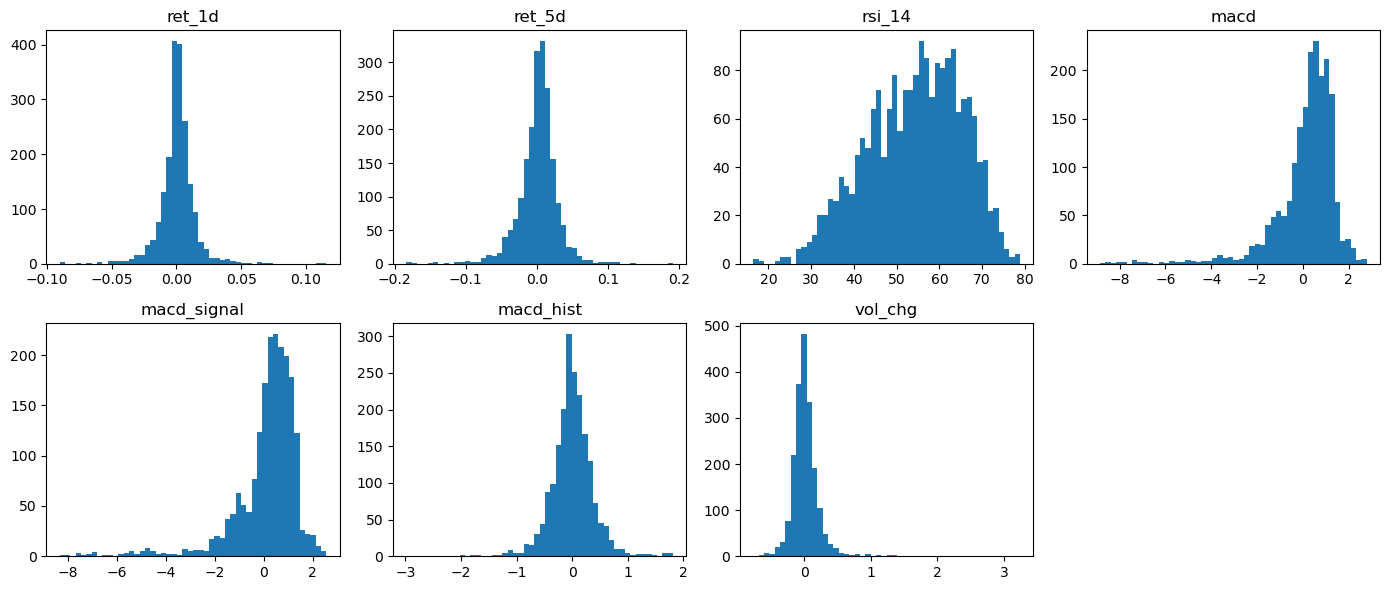

In [10]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, col in zip(axes.ravel(), TECH_COLS):
    ax.hist(features[col], bins=50)
    ax.set_title(col)
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

## 2.10 Leakage check

If any feature were secretly built from tomorrow's price, it would correlate strongly with the target.
For daily data these correlations should all be tiny, well under 0.1.

In [11]:
corr = features[TECH_COLS + ["target"]].corr()["target"].drop("target").round(3)
print(corr.to_string())
assert corr.abs().max() < 0.2, "A feature correlates too strongly with the target - check for leakage"
print("\nOK: no feature is suspiciously correlated with the target")

ret_1d        -0.057
ret_5d        -0.029
rsi_14        -0.041
macd          -0.007
macd_signal   -0.001
macd_hist     -0.023
vol_chg       -0.007

OK: no feature is suspiciously correlated with the target


## 2.11 Save

In [12]:
features.to_csv("data/features.csv", index=False)
print("saved data/features.csv with", len(features), "rows")
features.head()

saved data/features.csv with 1979 rows


,Date,Close,Volume,ret_1d,ret_5d,rsi_14,macd,macd_signal,macd_hist,vol_chg,target
0,2008-08-21,1277.719971,4032590000,0.002495,-0.011764,34.088826,0.360295,0.463422,-0.103126,-0.114695,1
1,2008-08-22,1292.199951,3741070000,0.011333,-0.004622,39.762473,0.408332,0.448249,-0.039917,-0.072291,0
2,2008-08-25,1266.839966,3420600000,-0.019625,-0.009198,34.208509,0.293685,0.424515,-0.130830,-0.085663,1
3,2008-08-26,1271.510010,3587570000,0.003686,0.003805,35.981839,0.222697,0.382904,-0.160207,0.048813,1
4,2008-08-27,1281.660034,3499610000,0.007983,0.005586,39.780971,0.227252,0.349348,-0.122096,-0.024518,1


**Done with step 2 when** `data/features.csv` exists, there are no missing values, and the leakage check passes.
Next: step 3, the Kaggle news data and FinBERT sentiment.